# Lecture 8 — Class Exercise
## Choropleth Maps

> **Push to:** `week08/lecture08_exercise.ipynb`

**Rules:**
1. Use `px.choropleth` or `px.choropleth_map` — choose deliberately and state your reason
2. Right colour scale for your data (sequential vs diverging) — state which and why
3. Insight title names a geographic finding — not just a topic
4. `featureidkey` must be correctly matched to your GeoJSON

---


> **Submission note:** This file was uploaded as `lecture06_exercise.ipynb`, but the assignment heading and required Git path identify it as **Lecture 8**. Both original tasks have been completed, and static map previews are embedded in the executed notebook as well as provided as PNG files. The two source data files are included in the accompanying ZIP so the notebook can be rerun offline (apart from any external Plotly base-map resources).

In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import json


## Task 1 — World choropleth: life expectancy diverging scale

**What to build:** A world choropleth showing **life expectancy relative to the global average** using a diverging colour scale.

**Requirements:**
- Use the Gapminder dataset for 2007: `px.data.gapminder()`
- Compute each country's deviation from the global mean life expectancy
- Diverging scale centred at zero (= world average)
- `hover_data` showing country name, raw life expectancy, and deviation
- Insight title naming which region is furthest below average

> 💡 `gm_2007['lifeExp'].mean()` gives you the global average to subtract from


2007 global mean life expectancy: 67.01 years
Mean life expectancy by continent (years):
continent lifeExp deviation_years
   Africa   54.81          -12.20
     Asia   70.73           +3.72
 Americas   73.61           +6.60
   Europe   77.65          +10.64
  Oceania   80.72          +13.71


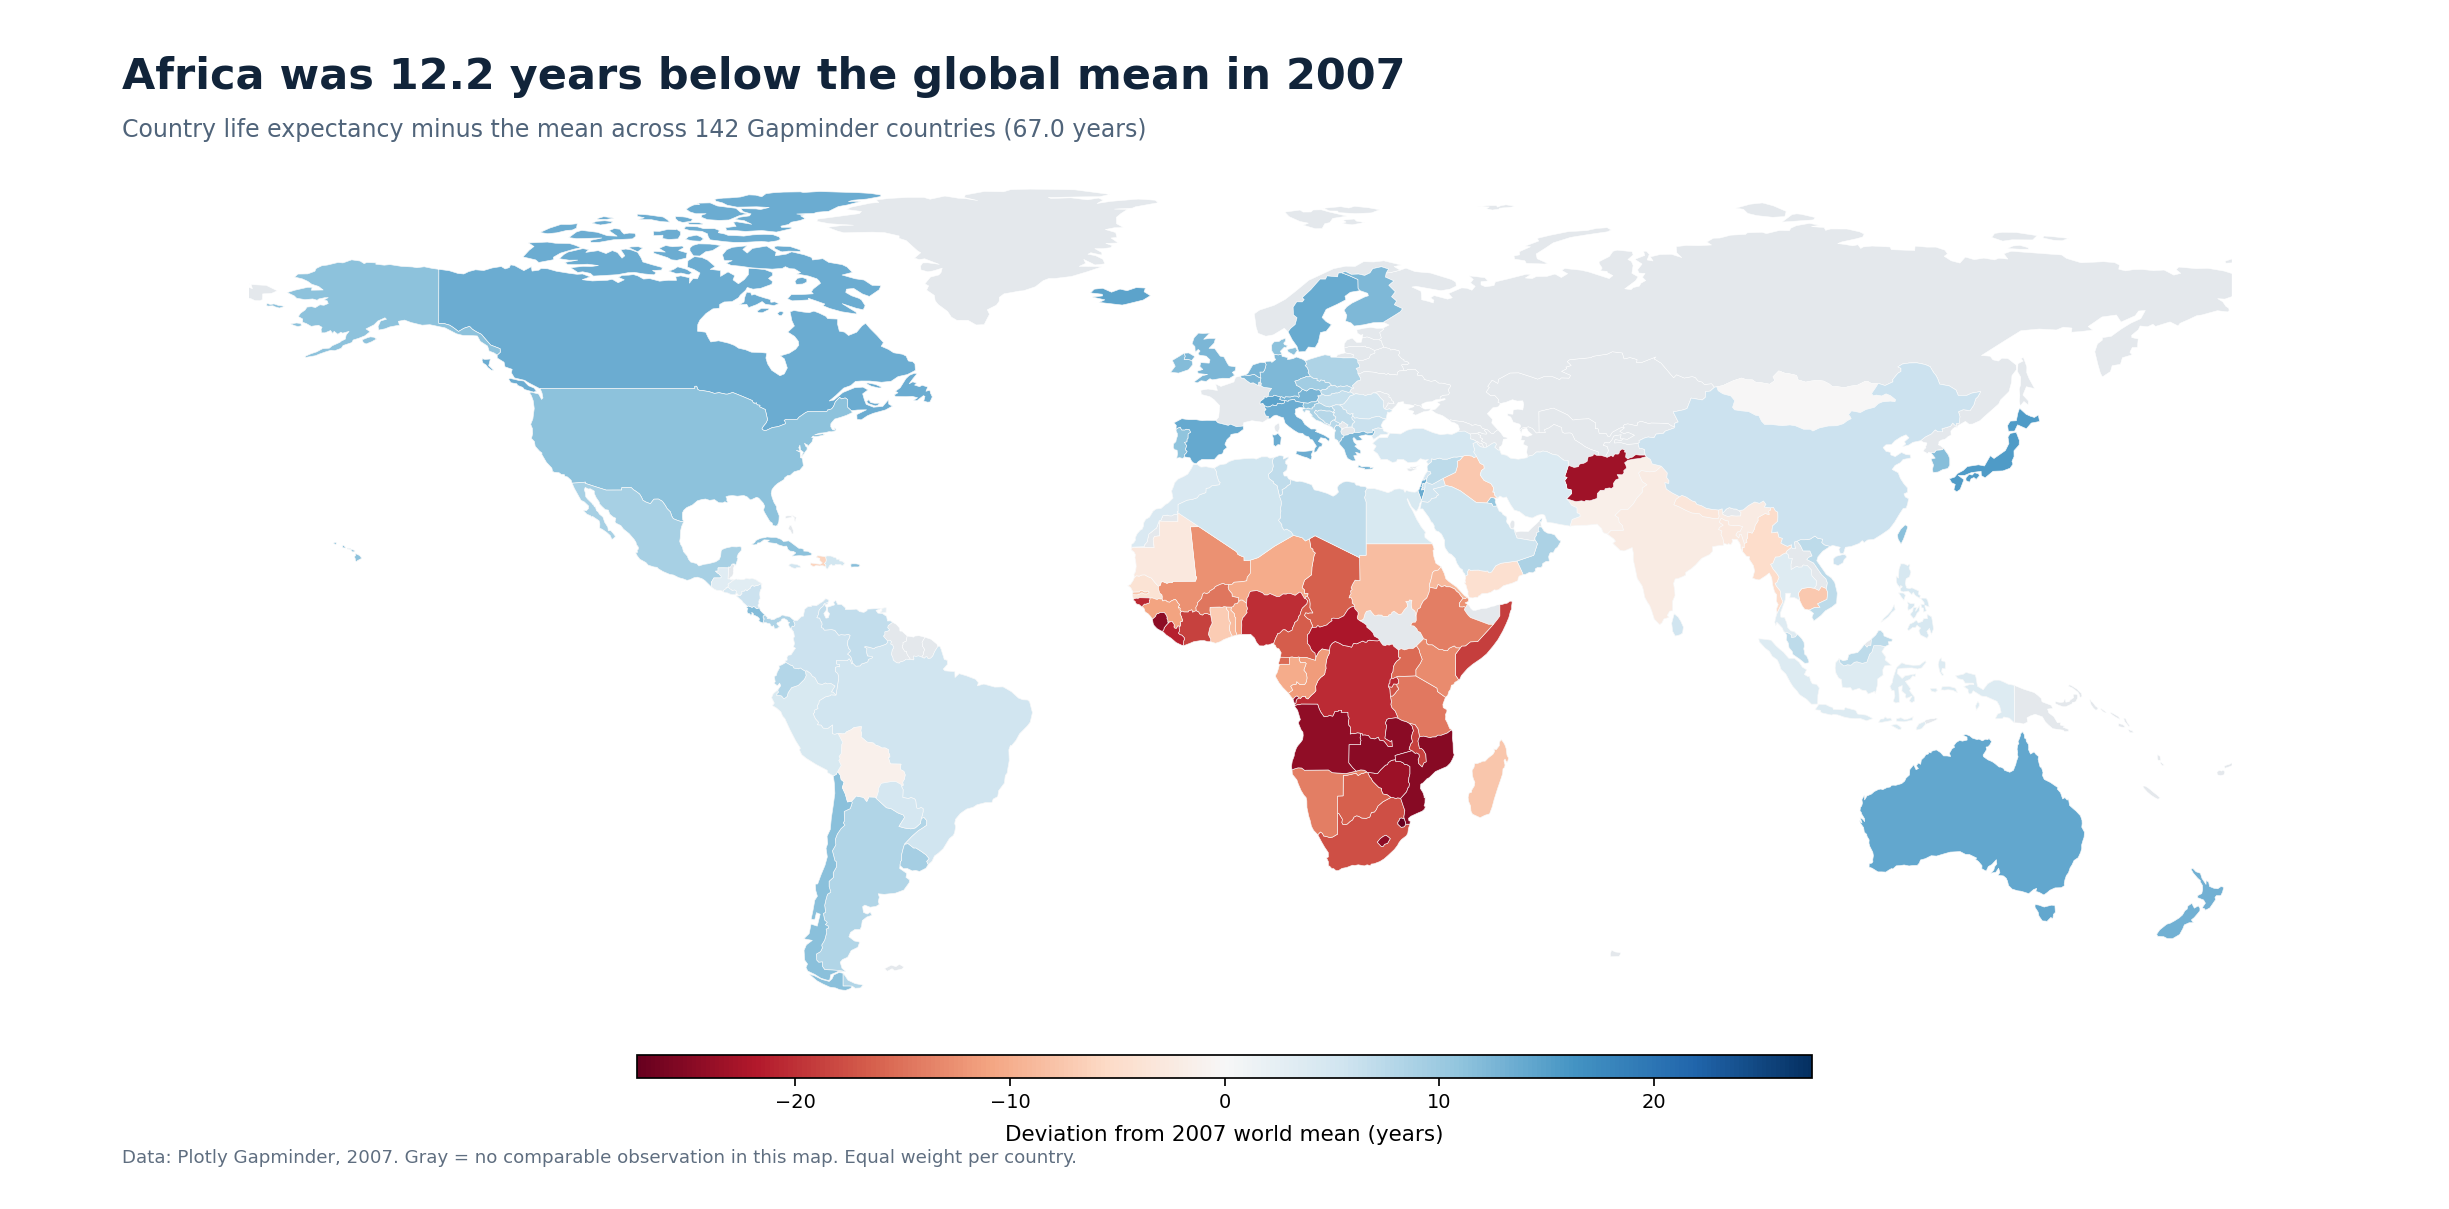

In [2]:
# Task 1 — World life expectancy relative to the country-level global mean (2007)
# We use px.choropleth because ISO-3 country codes already map to Plotly's
# built-in world geometry; no external map tiles or custom GeoJSON are needed.
gm_2007 = px.data.gapminder().query("year == 2007").copy()
global_mean = gm_2007["lifeExp"].mean()                 # unweighted mean of the 142 countries
gm_2007["deviation_years"] = gm_2007["lifeExp"] - global_mean

continent_summary = (gm_2007.groupby("continent", as_index=False)["lifeExp"]
                     .mean().sort_values("lifeExp"))
continent_summary["deviation_years"] = continent_summary["lifeExp"] - global_mean
lowest_region = continent_summary.iloc[0]
max_abs_dev = gm_2007["deviation_years"].abs().max()

print(f"2007 global mean life expectancy: {global_mean:.2f} years")
print("Mean life expectancy by continent (years):")
print(continent_summary.to_string(index=False, formatters={"lifeExp": "{:.2f}".format,
      "deviation_years": "{:+.2f}".format}))

fig_world = px.choropleth(
    gm_2007,
    locations="iso_alpha",               # ISO alpha-3 country codes
    locationmode="ISO-3",
    color="deviation_years",
    hover_name="country",
    hover_data={"continent": True, "lifeExp": ":.1f", "deviation_years": ":+.1f",
                "iso_alpha": False},
    color_continuous_scale="RdBu",       # diverging: below 0 red, above 0 blue
    color_continuous_midpoint=0,
    range_color=(-max_abs_dev, max_abs_dev),  # symmetric scale about the global mean
    projection="natural earth",
    labels={"lifeExp": "Life expectancy (years)",
            "deviation_years": "Difference from mean (years)",
            "continent": "Continent"},
    title=(f"{lowest_region['continent']} is {abs(lowest_region['deviation_years']):.1f} years "
           f"below the 2007 world average")
)
fig_world.update_geos(showframe=False, showcoastlines=True, coastlinecolor="white",
                      showland=True, landcolor="#e9edf1")
fig_world.update_layout(height=550, margin=dict(l=12,r=12,t=75,b=25),
                        coloraxis_colorbar=dict(title="Years vs mean"))
fig_world.show()

# Static image fallback, included in the submission bundle and embedded in saved output.
# This lets notebook viewers see a real map even when Plotly/TopoJSON cannot load.
from pathlib import Path
from IPython.display import Image, display
if Path("lecture08_task1_world.png").is_file():
    display(Image(filename="lecture08_task1_world.png"))


### Task 1 — Interpretation and design rationale

- **Geographical finding:** Africa has the lowest continental average life expectancy in 2007, at **54.8 years**, or **-12.2 years** relative to the **67.0-year global mean**. “Global mean” means an *unweighted country mean*, as required by the exercise (not a population-weighted average).
- **Chart choice:** `px.choropleth` is appropriate because Plotly already knows country boundaries from three-letter ISO codes (`locations="iso_alpha"`, `locationmode="ISO-3"`).
- **Colour choice:** **Diverging `RdBu`**, with its midpoint at exactly **0**, distinguishes countries below and above the mean. A symmetric range ensures comparable colour strength for equal positive and negative deviations.
- **Hover:** Country name, continent, original life expectancy in years, and deviation from the world mean.


## Task 2 — Find your own GeoJSON

**What to build:** A choropleth using a GeoJSON file you find yourself online.

**Requirements:**
- Find a free GeoJSON file for any geography that interests you (country, region, city)
- Create or find a matching dataset with at least one numeric variable per region
- Build either a `px.choropleth` or `px.choropleth_mapbox` — state your choice and reason in the markdown cell below
- Correctly identify and set `featureidkey` by inspecting the GeoJSON properties
- Choose sequential or diverging scale — state your reason in the markdown cell below
- Insight title naming a geographic finding

**Where to find GeoJSON files:**
- [geojson.xyz](https://geojson.xyz/) — countries, cities, natural features
- [naturalearthdata.com](https://www.naturalearthdata.com/) — global admin boundaries
- [github.com/datasets/geo-countries](https://github.com/datasets/geo-countries) — country polygons
- Search: `[country name] [admin level] GeoJSON github` — most countries have free boundary files on GitHub

> 💡 Before plotting, always inspect your GeoJSON properties first:
> ```python
> print(my_geojson['features'][0]['properties'])
> ```
> The property name that matches your dataframe's location column is what goes in `featureidkey='properties.???'`


### Task 2 — Design decisions

**GeoJSON source:** [Plotly open datasets — `election.geojson`](https://github.com/plotly/datasets/blob/master/election.geojson) (2013 Montréal mayoral-election electoral district polygons; [raw GeoJSON](https://raw.githubusercontent.com/plotly/datasets/master/election.geojson)). The file is included here as **`montreal_districts.geojson`**.

**Matching numeric dataset:** [Plotly open datasets — `election.csv`](https://github.com/plotly/datasets/blob/master/election.csv), included here as **`montreal_election_2013.csv`**. There is one row per electoral district (58 districts). I calculated **Coderre vote share (%) = 100 × Coderre votes ÷ total votes** for each district.

**Chart type chosen:** **`px.choropleth`**, not `px.choropleth_mapbox`, because these are custom polygons and a standard geographic projection displays them directly without an online map-tile service or a Mapbox token. The chart is an interactive choropleth.

**`featureidkey` chosen:** **`properties.district`**. The first GeoJSON feature has a `properties` dictionary with a `district` name; this matches the dataframe's cleaned `district_geo` column. Inspection also discovered a real-world naming mismatch: CSV `112-DeLorimier` vs GeoJSON `112-De Lorimier`. I corrected the spacing in a *separate matching column* and checked that **all 58 locations match**.

**Colour scale chosen:** **Sequential `Blues`**, because vote share is a nonnegative quantity (0–100%); darker blue simply means a higher percentage. A diverging scale would incorrectly imply a meaningful zero-centred “below vs above” sign change.

**Insight:** Ovide-Clermont had Coderre's **highest share (77.3%)** among the 58 electoral districts. This reflects the **2013 election**, not current voting preferences.


GeoJSON type: FeatureCollection
Number of GeoJSON district features: 58
First feature properties: {'district': '11-Sault-au-Récollet'}
First feature id: 11
Every district matched: 58/58
Highest Coderre vote share: 82-Ovide-Clermont — 77.3%


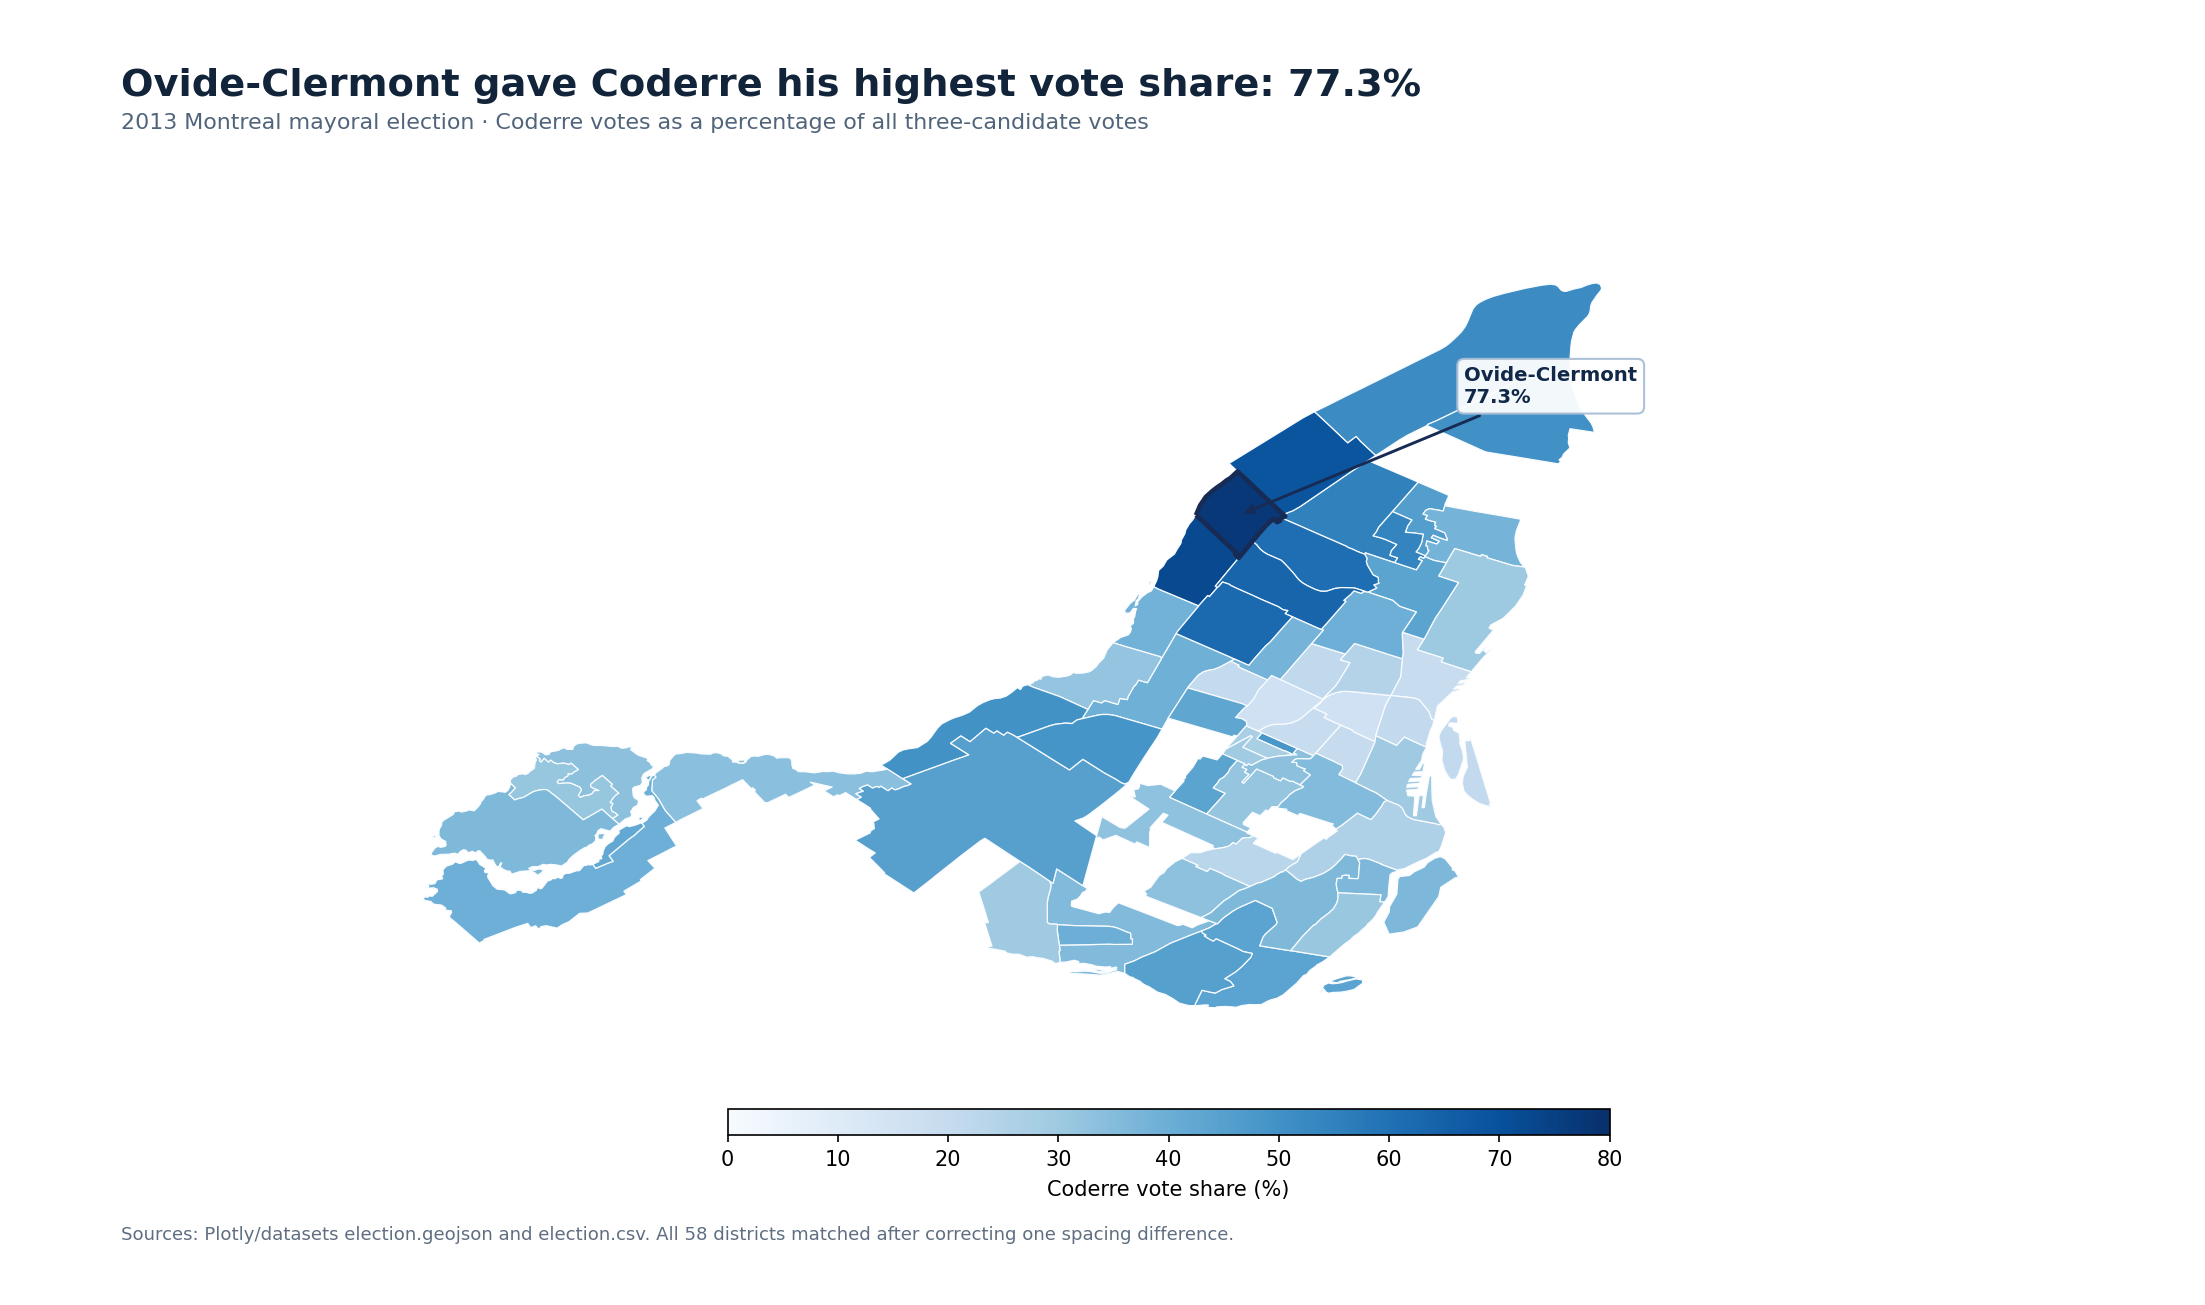

In [3]:
# Task 2 — Montreal 2013 election choropleth with our OWN sourced GeoJSON.
# The two data files are bundled alongside this notebook for offline reuse.
from pathlib import Path
geo_path = Path("montreal_districts.geojson")
vote_path = Path("montreal_election_2013.csv")
# With the ZIP supplied, both files are already present (no internet needed).
# For a notebook downloaded on its own, fetch copies from the same public source;
# Plotly's bundled copies also work if internet access is unavailable.
if not geo_path.exists():
    try:
        from urllib.request import urlretrieve
        urlretrieve("https://raw.githubusercontent.com/plotly/datasets/master/election.geojson", geo_path)
    except Exception:
        with geo_path.open("w", encoding="utf-8") as out:
            json.dump(px.data.election_geojson(), out, ensure_ascii=False)
if not vote_path.exists():
    try:
        from urllib.request import urlretrieve
        urlretrieve("https://raw.githubusercontent.com/plotly/datasets/master/election.csv", vote_path)
    except Exception:
        px.data.election().to_csv(vote_path, index=False)
with open(geo_path, "r", encoding="utf-8") as file:
    my_geojson = json.load(file)

print("GeoJSON type:", my_geojson["type"])
print("Number of GeoJSON district features:", len(my_geojson["features"]))
print("First feature properties:", my_geojson["features"][0]["properties"])
print("First feature id:", my_geojson["features"][0].get("id"))
# This confirms the correct property is featureidkey="properties.district".

election = pd.read_csv(vote_path)
# Fix a spacing inconsistency between the source CSV and source GeoJSON.
# Keep the original label for human-readable hover text.
election["district_geo"] = election["district"].replace(
    {"112-DeLorimier": "112-De Lorimier"}
)
election["coderre_pct"] = 100 * election["Coderre"] / election["total"]

geo_districts = {f["properties"]["district"] for f in my_geojson["features"]}
data_districts = set(election["district_geo"])
assert len(geo_districts) == len(election) == 58, "Unexpected district count"
assert data_districts == geo_districts, "GeoJSON featureidkey/district mismatch"
assert election["coderre_pct"].between(0,100).all(), "Vote share outside 0–100%"

highest = election.loc[election["coderre_pct"].idxmax()]
print(f"Every district matched: {len(data_districts)}/58")
print(f"Highest Coderre vote share: {highest['district']} — {highest['coderre_pct']:.1f}%")

fig_montreal = px.choropleth(
    election,
    geojson=my_geojson,
    locations="district_geo",
    featureidkey="properties.district",   # verified from the actual GeoJSON properties
    color="coderre_pct",
    color_continuous_scale="Blues",         # sequential: low -> high percentage
    range_color=(0, 80),
    hover_name="district",
    hover_data={"district_geo": False, "Coderre": ":,", "total": ":,",
                "coderre_pct": ":.1f"},
    labels={"coderre_pct": "Coderre vote share (%)",
            "Coderre": "Coderre votes", "total": "Total votes"},
    projection="mercator",
    title=(f"{highest['district'].split('-',1)[-1]} had Montreal's highest Coderre vote "
           f"share ({highest['coderre_pct']:.1f}%) in 2013")
)
fig_montreal.update_geos(fitbounds="locations", visible=False)
fig_montreal.update_layout(height=650, margin=dict(l=10,r=10,t=75,b=20),
                          coloraxis_colorbar=dict(title="Vote share (%)"))
fig_montreal.show()

# Embedded static picture ensures the map is visible in simple notebook viewers too.
if Path("lecture08_task2_montreal.png").is_file():
    display(Image(filename="lecture08_task2_montreal.png"))


### Task 2 — Interpretation

The map shows how the **percentage** of district votes for candidate **Denis Coderre** varied across the 58 Montréal electoral districts in the **2013 mayoral election**. **Ovide-Clermont** ranks highest at **77.3%**; lighter districts gave him a smaller percentage. Using vote share rather than raw vote totals makes areas with different numbers of voters more comparable.

**Data checks:** GeoJSON feature properties were inspected before mapping; all 58 CSV district names matched the 58 GeoJSON properties after one documented spacing correction. The original GeoJSON and election dataset are bundled alongside the notebook.
